# CICIoT2023 — EDA Restart

Check that each dataset split exists, then count its rows in chunks and read its header to summarize its dimensions.

In [1]:
import sys
from pathlib import Path
import pandas as pd

repo_root = Path.cwd().resolve()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent
sys.path.insert(0, str(repo_root))

from src.batch.dataset_paths import dataset_root

dataset_dir = dataset_root()
files = {
    "Train": dataset_dir / "CICIOT23/train/train.csv",
    "Validation": dataset_dir / "CICIOT23/validation/validation.csv",
    "Test": dataset_dir / "CICIOT23/test/test.csv",
}

missing = [str(path) for path in files.values() if not path.is_file()]
if missing:
    raise FileNotFoundError("Missing dataset files:\n" + "\n".join(missing))

summary = []
for split, path in files.items():
    columns = len(pd.read_csv(path, nrows=0).columns)
    rows = sum(len(chunk) for chunk in pd.read_csv(path, chunksize=100_000))
    summary.append({
        "Split": split,
        "File size (MiB)": round(path.stat().st_size / 1024**2, 2),
        "Total rows": rows,
        "Columns": columns,
    })

summary_df = pd.DataFrame(summary)
display(summary_df.set_index("Split"))
print(f"Combined total rows: {summary_df['Total rows'].sum():,}")

,File size (MiB),Total rows,Columns
Split,,,
Train,1548.24,5491971,47
Validation,331.80,1176851,47
Test,331.84,1176851,47


Combined total rows: 7,845,673


**Finding.** The files contain 5,491,971 training rows and 1,176,851 rows each for validation and test, for 7,845,673 total. Each has 47 columns. Dimensions establish size, while the next check verifies the actual headers.

Compare the column names and order across the three splits, then inspect the training columns and first five records. These are the first records, not a representative random sample.

In [1]:
from pathlib import Path
import pandas as pd

from src.batch.dataset_paths import dataset_root

dataset_dir = dataset_root()
files = {
    "Train": dataset_dir / "CICIOT23/train/train.csv",
    "Validation": dataset_dir / "CICIOT23/validation/validation.csv",
    "Test": dataset_dir / "CICIOT23/test/test.csv",
}
headers = {split: pd.read_csv(path, nrows=0).columns.tolist() for split, path in files.items()}
match = headers["Train"] == headers["Validation"] == headers["Test"]
print(f"Column names and order match exactly across all splits: {match}")

columns = pd.DataFrame({"Column name": headers["Train"]})
columns.index = pd.RangeIndex(1, len(columns) + 1, name="Number")
display(columns)

first_records = pd.read_csv(files["Train"], nrows=5)
display(first_records.T)

Column names and order match exactly across all splits: True


,Column name
Number,
1,flow_duration
2,Header_Length
3,Protocol Type
4,Duration
5,Rate
6,Srate
7,Drate
8,fin_flag_number
9,syn_flag_number


,0,1,2,3,4
flow_duration,0.0,0.0,0.033982,0.0,3.944828
Header_Length,757.0,54.0,56.78,0.0,108.0
Protocol Type,6.0,6.0,6.11,47.0,6.0
Duration,64.0,64.0,64.64,64.0,64.0
Rate,23.671858,2.393046,1.192715,9.841972,0.506993
Srate,23.671858,2.393046,1.192715,9.841972,0.506993
Drate,0.0,0.0,0.0,0.0,0.0
fin_flag_number,0.0,0.0,0.0,0.0,0.0
syn_flag_number,0.0,1.0,0.0,0.0,1.0
rst_flag_number,0.0,0.0,0.0,0.0,0.0


**Finding.** The three headers match exactly, with 46 feature columns and one label column. The first five training records show a few example values. Distribution and rarity require broader evidence.

We are checking original traffic-label frequencies before choosing stratified random subsets, so rare labels are not accidentally overlooked.

In [ ]:
from pathlib import Path
import pandas as pd

from src.batch.dataset_paths import dataset_root

dataset_dir = dataset_root()
files = {
    "Train": dataset_dir / "CICIOT23/train/train.csv",
    "Validation": dataset_dir / "CICIOT23/validation/validation.csv",
    "Test": dataset_dir / "CICIOT23/test/test.csv",
}
row_totals = summary_df.set_index("Split")["Total rows"]
counts = {}
missing_counts = {}
for split, path in files.items():
    split_counts = pd.Series(dtype="int64")
    missing_count = 0
    for chunk in pd.read_csv(path, usecols=["label"], chunksize=100_000):
        labels = chunk["label"]
        split_counts = split_counts.add(labels.value_counts(), fill_value=0)
        missing_count += labels.isna().sum()
    counts[split] = split_counts.astype("int64")
    missing_counts[split] = missing_count
    assert int(split_counts.sum()) + missing_count == row_totals[split], f"Label total mismatch for {split}"

label_table = pd.DataFrame(index=sorted(set().union(*(counts[s].index for s in files))))
label_table.index.name = "Label"
for split in files:
    label_table[f"{split} count"] = counts[split].reindex(label_table.index, fill_value=0)
    label_table[f"{split} %"] = (label_table[f"{split} count"] / row_totals[split] * 100).round(4)
display(label_table)
print("Missing labels: " + ", ".join(f"{split}: {count:,}" for split, count in missing_counts.items()))
print("Label counts plus missing labels match the previously calculated row totals for all splits.")

,Train count,Train %,Validation count,Validation %,Test count,Test %
Label,,,,,,
Backdoor_Malware,392,0.0071,93,0.0079,89,0.0076
BenignTraffic,129538,2.3587,27519,2.3384,27709,2.3545
BrowserHijacking,665,0.0121,158,0.0134,134,0.0114
CommandInjection,620,0.0113,132,0.0112,119,0.0101
DDoS-ACK_Fragmentation,33581,0.6115,7194,0.6113,7292,0.6196
DDoS-HTTP_Flood,3371,0.0614,706,0.0600,709,0.0602
DDoS-ICMP_Flood,848088,15.4423,182011,15.4659,180447,15.3330
DDoS-ICMP_Fragmentation,53046,0.9659,11430,0.9712,11402,0.9689
DDoS-PSHACK_Flood,481254,8.7629,102985,8.7509,103326,8.7799


Missing labels: Train: 0, Validation: 0, Test: 0
Label counts plus missing labels match the previously calculated row totals for all splits.


**Finding.** Every counted row had a label. Benign traffic accounts for roughly 2.34–2.36% in each split, while `Uploading_Attack` has just 140 training rows. The label totals agree with the row counts. Frequencies describe class imbalance, while the overlap check addresses split independence.

## Stratified random subsets and class proportions

Within each existing split, we sample whole records separately for each original label. Stratification approximately preserves label proportions. It does not balance the classes or resolve overlap between splits. Class imbalance describes unequal label frequencies. Numerical feature skewness describes asymmetry in the distribution of a numerical feature.

In [3]:
from pathlib import Path
import pandas as pd

from src.batch.dataset_paths import dataset_root

dataset_dir = dataset_root()
files = {
    "Train": dataset_dir / "CICIOT23/train/train.csv",
    "Validation": dataset_dir / "CICIOT23/validation/validation.csv",
    "Test": dataset_dir / "CICIOT23/test/test.csv",
}
from collections import Counter

import numpy as np

subset_sizes = {"Train": 100_000, "Validation": 25_000, "Test": 25_000}
chunk_size = 50_000
# Preserve literal CSV field values and treat empty labels as missing.
csv_options = {"keep_default_na": False, "skip_blank_lines": False}

# Saved counts from the preceding label inspection, checked against its row totals
# and recorded file sizes. For changed files, read only the label column in chunks.
saved_labels = ['Backdoor_Malware', 'BenignTraffic', 'BrowserHijacking', 'CommandInjection', 'DDoS-ACK_Fragmentation', 'DDoS-HTTP_Flood', 'DDoS-ICMP_Flood', 'DDoS-ICMP_Fragmentation', 'DDoS-PSHACK_Flood', 'DDoS-RSTFINFlood', 'DDoS-SYN_Flood', 'DDoS-SlowLoris', 'DDoS-SynonymousIP_Flood', 'DDoS-TCP_Flood', 'DDoS-UDP_Flood', 'DDoS-UDP_Fragmentation', 'DNS_Spoofing', 'DictionaryBruteForce', 'DoS-HTTP_Flood', 'DoS-SYN_Flood', 'DoS-TCP_Flood', 'DoS-UDP_Flood', 'MITM-ArpSpoofing', 'Mirai-greeth_flood', 'Mirai-greip_flood', 'Mirai-udpplain', 'Recon-HostDiscovery', 'Recon-OSScan', 'Recon-PingSweep', 'Recon-PortScan', 'SqlInjection', 'Uploading_Attack', 'VulnerabilityScan', 'XSS']
saved_counts = {
    'Train': [392, 129538, 665, 620, 33581, 3371, 848088, 53046, 481254, 475441, 478653, 2757, 422083, 528499, 637558, 34169, 21214, 1541, 8487, 237573, 314174, 390422, 36316, 116133, 88821, 104814, 15737, 11587, 249, 9648, 590, 140, 4396, 414],
    'Validation': [93, 27519, 158, 132, 7194, 706, 182011, 11430, 102985, 101563, 102644, 620, 90795, 113888, 136466, 7221, 4565, 290, 1833, 51115, 67056, 83446, 7741, 24910, 18867, 22314, 3482, 2500, 45, 2083, 148, 35, 905, 91],
    'Test': [89, 27709, 134, 119, 7292, 709, 180447, 11402, 103326, 101819, 102208, 622, 90480, 113735, 136717, 7224, 4570, 319, 1805, 51116, 67697, 83627, 7840, 24934, 19279, 22536, 3331, 2433, 53, 2082, 148, 33, 913, 103],
}
saved_missing = {'Train': 0, 'Validation': 0, 'Test': 0}
saved_file_stats = {'Train': (1623446296, 1794863541742735483), 'Validation': (347921865, 1794863543910373465), 'Test': (347958926, 1794863532455238655)}

full_counts = {}
missing_labels = {}
for split, source in files.items():
    stat = source.stat()
    if (stat.st_size, stat.st_mtime_ns) == saved_file_stats[split]:
        full_counts[split] = Counter(dict(zip(saved_labels, saved_counts[split], strict=True)))
        missing_labels[split] = saved_missing[split]
        continue
    counts = Counter()
    for chunk in pd.read_csv(
        source, usecols=["label"], dtype=str, chunksize=chunk_size, **csv_options
    ):
        counts.update(chunk["label"].fillna("").value_counts().to_dict())
    missing_labels[split] = counts.pop("", 0)
    full_counts[split] = counts

print("Missing labels — " + ", ".join(
    f"{split}: {count:,}" for split, count in missing_labels.items()
))
if any(missing_labels.values()):
    raise ValueError("Review missing labels before sampling.")

allocations = {}
for split, requested in subset_sizes.items():
    counts = full_counts[split]
    total = counts.total()
    if not 0 < requested <= total:
        raise ValueError(f"{split}: requested {requested:,} records from {total:,} available.")
    # Give leftover places to the largest fractional remainders. Break ties by label.
    quotas = {label: divmod(count * requested, total) for label, count in counts.items() if count}
    allocated = {label: whole for label, (whole, _) in quotas.items()}
    remaining = requested - sum(allocated.values())
    for label in sorted(quotas, key=lambda label: (-quotas[label][1], label))[:remaining]:
        allocated[label] += 1
    allocations[split] = allocated

sparse = [
    {"Split": split, "Label": label, "Allocated": count}
    for split, allocated in allocations.items()
    for label, count in sorted(allocated.items())
    if count < 20
]
if sparse:
    print("Sparse allocations (fewer than 20 records)")
    display(pd.DataFrame(sparse).set_index(["Split", "Label"]))
if any(row["Allocated"] == 0 for row in sparse):
    zero_labels = [f'{row["Split"]} / {row["Label"]}' for row in sparse if row["Allocated"] == 0]
    raise ValueError("Review subset sizes before sampling. Zero allocations: " + ", ".join(zero_labels))


Missing labels — Train: 0, Validation: 0, Test: 0
Sparse allocations (fewer than 20 records)


Allocated
Split      Label                          
Train      Backdoor_Malware              7
           BrowserHijacking             12
           CommandInjection             11
           Recon-PingSweep               5
           SqlInjection                 11
           Uploading_Attack              3
           XSS                           8
Validation Backdoor_Malware              2
           BrowserHijacking              3
           CommandInjection              3
           DDoS-HTTP_Flood              15
           DDoS-SlowLoris               13
           DictionaryBruteForce          6
           Recon-PingSweep               1
           SqlInjection                  3
           Uploading_Attack              1
           VulnerabilityScan            19
           XSS                           2
Test       Backdoor_Malware              2
           BrowserHijacking              3
           CommandInjection              3
           DDoS-HTTP_Flood              15
           DDoS-SlowLoris               13
           DictionaryBruteForce          7
           Recon-PingSweep               1
           SqlInjection                  3
           Uploading_Attack              1
           VulnerabilityScan            19
           XSS                           2

In [4]:
from tempfile import TemporaryDirectory

subset_dir = repo_root / "data/subsets"
subset_paths = {
    split: subset_dir / f"ciciot2023_{split.lower()}_stratified_{size}_seed42.csv"
    for split, size in subset_sizes.items()
}
existing = [path for path in subset_paths.values() if path.exists() or path.is_symlink()]
if existing:
    raise FileExistsError("Subset files already exist:\n" + "\n".join(map(str, existing)))

rng = np.random.default_rng(42)
subset_dir.mkdir(parents=True, exist_ok=True)
with TemporaryDirectory(dir=subset_dir) as staging:
    for split, source in files.items():
        # Draw positions in each label's full-file sequence, then resolve them in one pass.
        positions = {
            label: np.sort(rng.choice(full_counts[split][label], size, replace=False))
            for label, size in sorted(allocations[split].items())
        }
        seen = Counter()
        selected = Counter()
        staged_path = Path(staging) / subset_paths[split].name
        with staged_path.open("w", encoding="utf-8", newline="") as output:
            for chunk_number, chunk in enumerate(pd.read_csv(
                source, dtype=str, chunksize=chunk_size, **csv_options
            )):
                if chunk_number == 0:
                    chunk.head(0).to_csv(output, index=False)
                keep = np.zeros(len(chunk), dtype=bool)
                for label, indices in chunk.groupby("label", sort=False, dropna=False).indices.items():
                    if label not in positions:
                        raise ValueError(f"{split}: unexpected label {label!r}.")
                    start = seen[label]
                    seen[label] += len(indices)
                    ranks = positions[label]
                    left, right = ranks.searchsorted([start, seen[label]])
                    keep[indices[ranks[left:right] - start]] = True
                    selected[label] += right - left
                chunk.loc[keep].to_csv(output, index=False, header=False)
        if seen != full_counts[split] or selected != Counter(allocations[split]):
            raise ValueError(f"{split}: label counts changed or the sample is incomplete.")

    published = []
    try:
        for destination in subset_paths.values():
            # Linking publishes a complete file and fails if the destination exists.
            destination.hardlink_to(Path(staging) / destination.name)
            published.append(destination)
    except OSError:
        for destination in published:
            destination.unlink()
        raise


,Saved path,Rows
Split,,
Train,data/subsets/ciciot2023_train_stratified_100000_seed42.csv,100000
Validation,data/subsets/ciciot2023_validation_stratified_25000_seed42.csv,25000
Test,data/subsets/ciciot2023_test_stratified_25000_seed42.csv,25000


Train                       Validation               \
                         Full % Subset count Subset %     Full % Subset count   
Label                                                                           
Backdoor_Malware         0.0071            7   0.0070     0.0079            2   
BenignTraffic            2.3587         2359   2.3590     2.3384          585   
BrowserHijacking         0.0121           12   0.0120     0.0134            3   
CommandInjection         0.0113           11   0.0110     0.0112            3   
DDoS-ACK_Fragmentation   0.6115          611   0.6110     0.6113          153   
DDoS-HTTP_Flood          0.0614           61   0.0610     0.0600           15   
DDoS-ICMP_Flood         15.4423        15442  15.4420    15.4659         3867   
DDoS-ICMP_Fragmentation  0.9659          966   0.9660     0.9712          243   
DDoS-PSHACK_Flood        8.7629         8763   8.7630     8.7509         2188   
DDoS-RSTFINFlood         8.6570         8657   8.6570     8.6301         2158   
DDoS-SYN_Flood           8.7155         8715   8.7150     8.7219         2180   
DDoS-SlowLoris           0.0502           50   0.0500     0.0527           13   
DDoS-SynonymousIP_Flood  7.6855         7685   7.6850     7.7151         1929   
DDoS-TCP_Flood           9.6231         9623   9.6230     9.6774         2419   
DDoS-UDP_Flood          11.6089        11609  11.6090    11.5959         2899   
DDoS-UDP_Fragmentation   0.6222          622   0.6220     0.6136          153   
DNS_Spoofing             0.3863          386   0.3860     0.3879           97   
DictionaryBruteForce     0.0281           28   0.0280     0.0246            6   
DoS-HTTP_Flood           0.1545          155   0.1550     0.1558           39   
DoS-SYN_Flood            4.3258         4326   4.3260     4.3434         1086   
DoS-TCP_Flood            5.7206         5721   5.7210     5.6979         1424   
DoS-UDP_Flood            7.1090         7109   7.1090     7.0906         1773   
MITM-ArpSpoofing         0.6613          661   0.6610     0.6578          164   
Mirai-greeth_flood       2.1146         2115   2.1150     2.1167          529   
Mirai-greip_flood        1.6173         1617   1.6170     1.6032          401   
Mirai-udpplain           1.9085         1908   1.9080     1.8961          474   
Recon-HostDiscovery      0.2865          287   0.2870     0.2959           74   
Recon-OSScan             0.2110          211   0.2110     0.2124           53   
Recon-PingSweep          0.0045            5   0.0050     0.0038            1   
Recon-PortScan           0.1757          176   0.1760     0.1770           44   
SqlInjection             0.0107           11   0.0110     0.0126            3   
Uploading_Attack         0.0025            3   0.0030     0.0030            1   
VulnerabilityScan        0.0800           80   0.0800     0.0769           19   
XSS                      0.0075            8   0.0080     0.0077            2   

                                    Test                        
                        Subset %  Full % Subset count Subset %  
Label                                                           
Backdoor_Malware          0.0080  0.0076            2   0.0080  
BenignTraffic             2.3400  2.3545          589   2.3560  
BrowserHijacking          0.0120  0.0114            3   0.0120  
CommandInjection          0.0120  0.0101            3   0.0120  
DDoS-ACK_Fragmentation    0.6120  0.6196          155   0.6200  
DDoS-HTTP_Flood           0.0600  0.0602           15   0.0600  
DDoS-ICMP_Flood          15.4680 15.3330         3833  15.3320  
DDoS-ICMP_Fragmentation   0.9720  0.9689          242   0.9680  
DDoS-PSHACK_Flood         8.7520  8.7799         2195   8.7800  
DDoS-RSTFINFlood          8.6320  8.6518         2163   8.6520  
DDoS-SYN_Flood            8.7200  8.6849         2171   8.6840  
DDoS-SlowLoris            0.0520  0.0529           13   0.0520  
DDoS-SynonymousIP_Flood   7.7160  7.6883         1922

,Largest absolute difference (pp)
Split,
Train,0.0005
Validation,0.0021
Test,0.0020


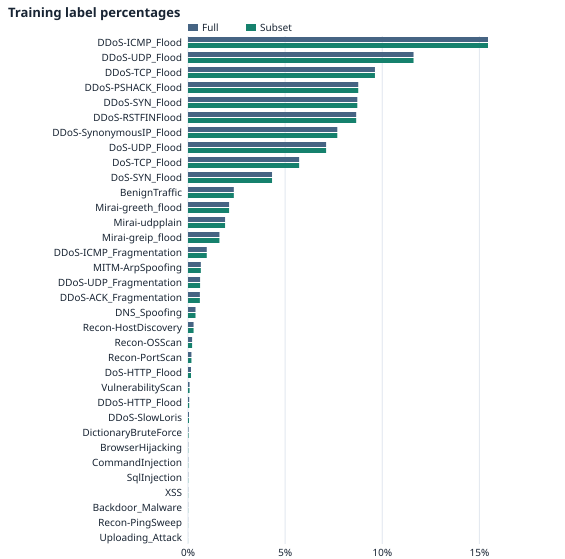

In [5]:
from html import escape

from IPython.display import SVG, display

saved_rows = {}
comparison = {}
max_differences = {}
labels = sorted(set().union(*(counts.keys() for counts in full_counts.values())))
for split, path in subset_paths.items():
    subset_counts = Counter()
    for chunk in pd.read_csv(path, usecols=["label"], dtype=str, chunksize=chunk_size, **csv_options):
        subset_counts.update(chunk["label"].value_counts().to_dict())
    if subset_counts != Counter(allocations[split]):
        raise ValueError(f"{path}: saved label counts differ from the allocation.")
    saved_rows[split] = {"Saved path": str(path), "Rows": subset_counts.total()}
    full_pct = pd.Series(full_counts[split]).reindex(labels, fill_value=0) / full_counts[split].total() * 100
    subset_count = pd.Series(subset_counts).reindex(labels, fill_value=0)
    subset_pct = subset_count / subset_counts.total() * 100
    comparison[split] = pd.DataFrame({
        "Full %": full_pct, "Subset count": subset_count, "Subset %": subset_pct
    })
    max_differences[split] = (subset_pct - full_pct).abs().max()

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame.from_dict(saved_rows, orient="index").rename_axis("Split"))
with pd.option_context("display.max_columns", None, "display.float_format", "{:.4f}".format):
    display(pd.concat(comparison, axis=1).rename_axis("Label"))
    display(pd.Series(max_differences, name="Largest absolute difference (pp)").rename_axis("Split").to_frame())

# Paired bars use the same linear scale across all training labels.
train = comparison["Train"].sort_values("Full %", ascending=False)
scale = 300 / train["Full %"].max()
height = 49 + 15 * len(train)
svg = [
    f'<svg xmlns="http://www.w3.org/2000/svg" width="565" height="{height}" '
    f'viewBox="0 0 565 {height}" role="img" aria-label="Training label percentages">',
    '<rect width="100%" height="100%" fill="white"/>',
    '<g font-family="sans-serif" fill="#182433" font-size="10">',
    '<text x="8" y="17" font-size="13" font-weight="bold">Training label percentages</text>',
    '<rect x="188" y="24" width="10" height="7" fill="#466483"/><text x="202" y="31">Full</text>',
    '<rect x="246" y="24" width="10" height="7" fill="#16816d"/><text x="260" y="31">Subset</text>',
]
for tick in (0, 5, 10, 15):
    x = 188 + scale * tick
    svg.append(f'<path d="M{x} 36 V{height - 15}" stroke="#e1e7ef"/>')
    svg.append(f'<text x="{x}" y="{height - 3}" text-anchor="middle">{tick}%</text>')
for index, (label, row) in enumerate(train.iterrows()):
    y = 37 + 15 * index
    full, subset = row["Full %"], row["Subset %"]
    svg.append(
        f'<g><title>{escape(label)} — full {full:.4f}%, subset {subset:.4f}%</title>'
        f'<text x="182" y="{y + 9}" text-anchor="end">{escape(label)}</text>'
        f'<rect x="188" y="{y}" width="{full * scale:.3f}" height="5" fill="#466483"/>'
        f'<rect x="188" y="{y + 6}" width="{subset * scale:.3f}" height="5" fill="#16816d"/>'
        '</g>'
    )
svg.append('</g></svg>')
display(SVG("".join(svg)))


**Finding.** The saved-file comparison verified 100,000 training rows and 25,000 rows each for validation and test. Largest label-share differences were 0.0005, 0.0021, and 0.0020 percentage points, respectively. Only three `Uploading_Attack` examples were allocated to training, limiting what can be inferred for that label.

## Data types and missing/non-finite values

We check column names, order, and pandas data types, then count missing values and both signs of infinity to spot data quality issues before analysis. Zeros count as valid values. Results apply only to the saved subsets.

In [6]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from pandas.api.types import is_numeric_dtype

audit_paths = {
    "Train": (repo_root / "data/subsets/ciciot2023_train_stratified_100000_seed42.csv"),
    "Validation": (repo_root / "data/subsets/ciciot2023_validation_stratified_25000_seed42.csv"),
    "Test": (repo_root / "data/subsets/ciciot2023_test_stratified_25000_seed42.csv"),
}
from src.batch.dataset_paths import dataset_root

if "headers" not in globals():
    original_dir = dataset_root() / "CICIOT23"
    headers = {
        split: pd.read_csv(
            original_dir / split.lower() / f"{split.lower()}.csv", nrows=0
        ).columns.tolist()
        for split in audit_paths
    }

# Reuse full subset dataframes on reruns.
if "subset_frames" not in globals():
    subset_frames = {}

summary_rows = []
column_audits = {}
non_numeric_features = {}
count_columns = ["Missing", "+inf", "-inf"]

for split, path in audit_paths.items():
    if split not in subset_frames:
        subset_frames[split] = pd.read_csv(path)
    frame = subset_frames[split]
    if frame.columns.tolist() != headers[split]:
        raise ValueError(f"{split}: column names or order differ from the original schema.")

    missing_mask = frame.isna()
    affected_rows = missing_mask.any(axis=1)
    audit = pd.DataFrame({
        "Data type": frame.dtypes,
        "Missing": missing_mask.sum(),
        "+inf": 0,
        "-inf": 0,
    }).rename_axis("Column")
    non_numeric_features[split] = []

    for column, dtype in frame.dtypes.items():
        if is_numeric_dtype(dtype):
            positive_inf = frame[column].eq(np.inf).fillna(False)
            negative_inf = frame[column].eq(-np.inf).fillna(False)
            audit.loc[column, "+inf"] = positive_inf.sum()
            audit.loc[column, "-inf"] = negative_inf.sum()
            affected_rows |= positive_inf | negative_inf
        elif column != "label":
            non_numeric_features[split].append(column)

    column_audits[split] = audit
    summary_rows.append({
        "Split": split,
        "Rows": len(frame),
        "Columns": frame.shape[1],
        "Missing cells": audit["Missing"].sum(),
        "+inf cells": audit["+inf"].sum(),
        "-inf cells": audit["-inf"].sum(),
        "Rows with any missing or infinite value": affected_rows.sum(),
    })

with pd.option_context("display.max_columns", None):
    display(pd.DataFrame(summary_rows).set_index("Split"))
print("Column names and order match the original schema for all three subsets.")
for split, columns in non_numeric_features.items():
    print(f"{split} non-numeric features (excluding label): " + (", ".join(columns) or "none"))

print("Training columns")
with pd.option_context("display.max_rows", None):
    display(column_audits["Train"].reset_index())

for split in ("Validation", "Test"):
    audit = column_audits[split]
    training_types = column_audits["Train"]["Data type"].reindex(audit.index)
    show = audit[count_columns].gt(0).any(axis=1) | audit["Data type"].ne(training_types)
    show |= audit.index.isin(non_numeric_features[split])
    if show.any():
        print(f"{split} columns with issues or data type differences")
        details = audit.loc[show].assign(**{"Training data type": training_types.loc[show]})
        with pd.option_context("display.max_rows", None):
            display(details.reset_index())


,Rows,Columns,Missing cells,+inf cells,-inf cells,Rows with any missing or infinite value
Split,,,,,,
Train,100000,47,0,0,0,0
Validation,25000,47,0,0,0,0
Test,25000,47,0,0,0,0


Column names and order match the original schema for all three subsets.
Train non-numeric features (excluding label): none
Validation non-numeric features (excluding label): none
Test non-numeric features (excluding label): none
Training columns


,Column,Data type,Missing,+inf,-inf
0,flow_duration,float64,0,0,0
1,Header_Length,float64,0,0,0
2,Protocol Type,float64,0,0,0
3,Duration,float64,0,0,0
4,Rate,float64,0,0,0
5,Srate,float64,0,0,0
6,Drate,float64,0,0,0
7,fin_flag_number,float64,0,0,0
8,syn_flag_number,float64,0,0,0
9,rst_flag_number,float64,0,0,0


**Finding.** All three saved subsets matched the original column order, with zero missing or infinite cells and zero affected rows. The 46 features were numeric and types matched across splits. These checks cover the subsets and leave feature meaning and plausible ranges to be investigated.

## Duplicates and cross-split overlap

We check for extra copies within each split and exact feature matches between splits. Training overlap can make validation or test scores look better because the model has already seen the same features.

Full-row duplicates include the label. Feature duplicates ignore it. A shared pattern counts once, while every row with that pattern contributes to its split's overlap percentage.

In [7]:
from collections import Counter
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from pandas.api.types import is_numeric_dtype

subset_dir = repo_root / "data/subsets"
overlap_sizes = {"Train": 100_000, "Validation": 25_000, "Test": 25_000}
# Parse each subset with the same options and compare the resulting values directly.
overlap_frames = {
    split: pd.read_csv(
        subset_dir / f"ciciot2023_{split.lower()}_stratified_{size}_seed42.csv",
        low_memory=False,
        skip_blank_lines=False,
    )
    for split, size in overlap_sizes.items()
}
feature_columns = overlap_frames["Train"].columns.drop("label", errors="ignore")
input_issues = []

for split, frame in overlap_frames.items():
    features = frame.columns.drop("label", errors="ignore")
    if "label" not in frame or not features.equals(feature_columns):
        input_issues.append(f"{split}: expected a label and the training feature columns in order.")
    for column, dtype in frame.dtypes.items():
        values = frame[column]
        missing = int(values.isna().sum())
        if missing:
            input_issues.append(f"{split} / {column}: {missing:,} missing cells.")
        if is_numeric_dtype(dtype):
            positive_inf = int(values.eq(np.inf).sum())
            negative_inf = int(values.eq(-np.inf).sum())
            if positive_inf or negative_inf:
                input_issues.append(
                    f"{split} / {column}: {positive_inf:,} +inf and {negative_inf:,} -inf cells."
                )
        elif column != "label":
            input_issues.append(f"{split} / {column}: non-numeric feature ({dtype}).")

if input_issues:
    print("\n".join(input_issues))
    raise ValueError("Overlap audit stopped because the saved subsets failed the input checks.")

pattern_counts = {}
within_rows = []
for split, frame in overlap_frames.items():
    patterns = {}
    for row in frame[[*feature_columns, "label"]].itertuples(index=False, name=None):
        feature_key, label = row[:-1], row[-1]
        # Dictionary lookups check the actual tuples for equality on hash matches.
        if feature_key not in patterns:
            patterns[feature_key] = Counter()
        patterns[feature_key][label] += 1

    pattern_counts[split] = patterns
    within_rows.append({
        "Split": split,
        "Total rows": len(frame),
        "Extra full-row copies": len(frame) - sum(map(len, patterns.values())),
        "Extra feature-row copies": len(frame) - len(patterns),
        "Feature patterns with multiple labels": sum(len(labels) > 1 for labels in patterns.values()),
    })

overlap_rows = []
for left, right in combinations(overlap_frames, 2):
    left_patterns = pattern_counts[left]
    right_patterns = pattern_counts[right]
    shared = left_patterns.keys() & right_patterns.keys()
    left_matches = sum(left_patterns[key].total() for key in shared)
    right_matches = sum(right_patterns[key].total() for key in shared)
    # Each split has at least one label for each shared key. A union of two or
    # more labels therefore means some label from one split differs from the other.
    conflicts = sum(
        len(left_patterns[key].keys() | right_patterns[key].keys()) > 1
        for key in shared
    )
    overlap_rows.append({
        "First split": left,
        "Second split": right,
        "Shared feature patterns": len(shared),
        "Matching rows (first)": left_matches,
        "Matching rows % (first)": 100 * left_matches / len(overlap_frames[left]),
        "Matching rows (second)": right_matches,
        "Matching rows % (second)": 100 * right_matches / len(overlap_frames[right]),
        "Shared patterns with conflicting labels": conflicts,
    })

with pd.option_context("display.max_columns", None, "display.float_format", "{:.4f}".format):
    display(pd.DataFrame(within_rows).set_index("Split"))
    display(pd.DataFrame(overlap_rows).set_index(["First split", "Second split"]))


,Total rows,Extra full-row copies,Extra feature-row copies,Feature patterns with multiple labels
Split,,,,
Train,100000,43,43,0
Validation,25000,4,4,0
Test,25000,6,6,0


Shared feature patterns  Matching rows (first)  \
First split Second split                                                   
Train       Validation                         25                     25   
            Test                               19                     19   
Validation  Test                                5                      5   

                          Matching rows % (first)  Matching rows (second)  \
First split Second split                                                    
Train       Validation                     0.0250                      25   
            Test                           0.0190                      19   
Validation  Test                           0.0200                       5   

                          Matching rows % (second)  \
First split Second split                             
Train       Validation                      0.1000   
            Test                            0.0760   
Validation  Test                            0.0200   

                          Shared patterns with conflicting labels  
First split Second split                                           
Train       Validation                                          0  
            Test                                                0  
Validation  Test                                                0

**Subset findings.** Train and validation shared 25 distinct patterns, covering 25 train rows and 25 validation rows. One pattern can account for several rows. Identical features alone do not prove that records came from the same real-world event. This subset audit does not establish independence of the full original splits.

## Feature variability and numerical summary

Use only the saved training subset for feature exploration. The saved data-quality audit already checked its schema, numeric types, and missing and infinite values. Count distinct values to distinguish constants, observed 0/1 indicators, and other features with at most 10 values. A numeric dtype or a small value count does not establish what a feature measures.

In [8]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import HTML, display

training_path = repo_root / "data/subsets/ciciot2023_train_stratified_100000_seed42.csv"
training_eda = pd.read_csv(training_path, low_memory=False, skip_blank_lines=False)
# The audited original schema has 46 features and one label. This CSV has no derived targets.
features_eda = training_eda.drop(columns="label").select_dtypes(include="number")
unique_counts = features_eda.nunique()
constant_columns = unique_counts[unique_counts.eq(1)].index.tolist()
binary_columns = [
    column for column in unique_counts[unique_counts.eq(2)].index
    if set(features_eda[column].unique()) == {0, 1}
]
other_low_columns = [
    column for column in unique_counts[unique_counts.between(2, 10)].index
    if column not in binary_columns
]
measurement_columns = unique_counts[unique_counts.gt(10)].index.tolist()

observed_values = pd.DataFrame([
    {"Feature": column, "Observed values": ", ".join(f"{value:g}" for value in sorted(features_eda[column].unique()))}
    for column in constant_columns + other_low_columns
])
display(pd.DataFrame({
    "Observed feature group": ["Constant", "Binary (0 and 1)", "Other low cardinality", "More than 10 values"],
    "Features": [len(constant_columns), len(binary_columns), len(other_low_columns), len(measurement_columns)],
}))
if not observed_values.empty:
    display(observed_values)
display(HTML(
    "<details><summary>Observed 0/1 features</summary><p>"
    + (", ".join(binary_columns) or "None") + "</p></details>"
))

quantiles = features_eda.quantile([0.5, 0.95, 0.99])
feature_summary = pd.DataFrame({
    "Unique values": unique_counts,
    "Zero %": features_eda.eq(0).mean() * 100,
    "Negative count": features_eda.lt(0).sum(),
    "Min": features_eda.min(),
    "Median": quantiles.loc[0.5],
    "Mean": features_eda.mean(),
    "Std dev": features_eda.std(),
    "P95": quantiles.loc[0.95],
    "P99": quantiles.loc[0.99],
    "Max": features_eda.max(),
}).rename_axis("Feature")
display(HTML(
    "<details><summary>Numerical summary for all 46 features</summary>"
    + feature_summary.to_html(float_format="{:.5g}".format)
    + "</details>"
))

,Observed feature group,Features
0,Constant,6
1,Binary (0 and 1),15
2,Other low cardinality,1
3,More than 10 values,24


,Feature,Observed values
0,ece_flag_number,0
1,cwr_flag_number,0
2,Telnet,0
3,SMTP,0
4,IRC,0
5,DHCP,0
6,Drate,"0, 0.00506246, 0.00650235, 0.0084162, 0.010037..."


,Unique values,Zero %,Negative count,Min,Median,Mean,Std dev,P95,P99,Max
Feature,,,,,,,,,,
flow_duration,45823,54.091,0,0,0,6.9538,331.21,5.8042,65.692,64235
Header_Length,27356,16.051,0,0,54,75946,4.5417e+05,1.0451e+05,2.2644e+06,9.6235e+06
Protocol Type,1160,0,0,0.77,6,9.0678,8.9402,17,47,47
Duration,2712,0,0,2,64,66.366,13.986,69.73,138.2,255
Rate,95245,2.038,0,0,15.9,9281.2,1.0243e+05,15892,1.2879e+05,8.3886e+06
Srate,95245,2.038,0,0,15.9,9281.2,1.0243e+05,15892,1.2879e+05,8.3886e+06
Drate,7,99.994,0,0,0,1.059e-06,0.0001897,0,0,0.053441
fin_flag_number,2,91.349,0,0,0,0.08651,0.28112,1,1,1
syn_flag_number,2,79.311,0,0,0,0.20689,0.40508,1,1,1


**Finding.** 6 features were constant (`ece_flag_number`, `cwr_flag_number`, `Telnet`, `SMTP`, `IRC`, `DHCP`), 15 took both 0 and 1, and 1 other features had at most 10 observed values (`Drate`). A value absent from this sample may occur elsewhere.

## Distributions and skewness

Calculate skewness for all nonconstant numeric features, then report the strongest asymmetry separately for features with many observed values and for binary or other low-cardinality features. Inspect five measurements in the original scale and in a signed-log view that makes the center visible while retaining zeros, negatives, and the full range.

Unique values  Skewness
Observed feature group          Feature                               
Many observed values            flow_duration          45823    128.34
                                Covariance             18889     32.86
                                urg_count               2489     25.70
                                Rate                   95245     25.35
                                Srate                  95245     25.35
Binary or other low cardinality Drate                      7    243.04
                                SSH                        2    129.09
                                ARP                        2    129.09
                                IPv                        2    -91.27
                                LLC                        2    -91.27

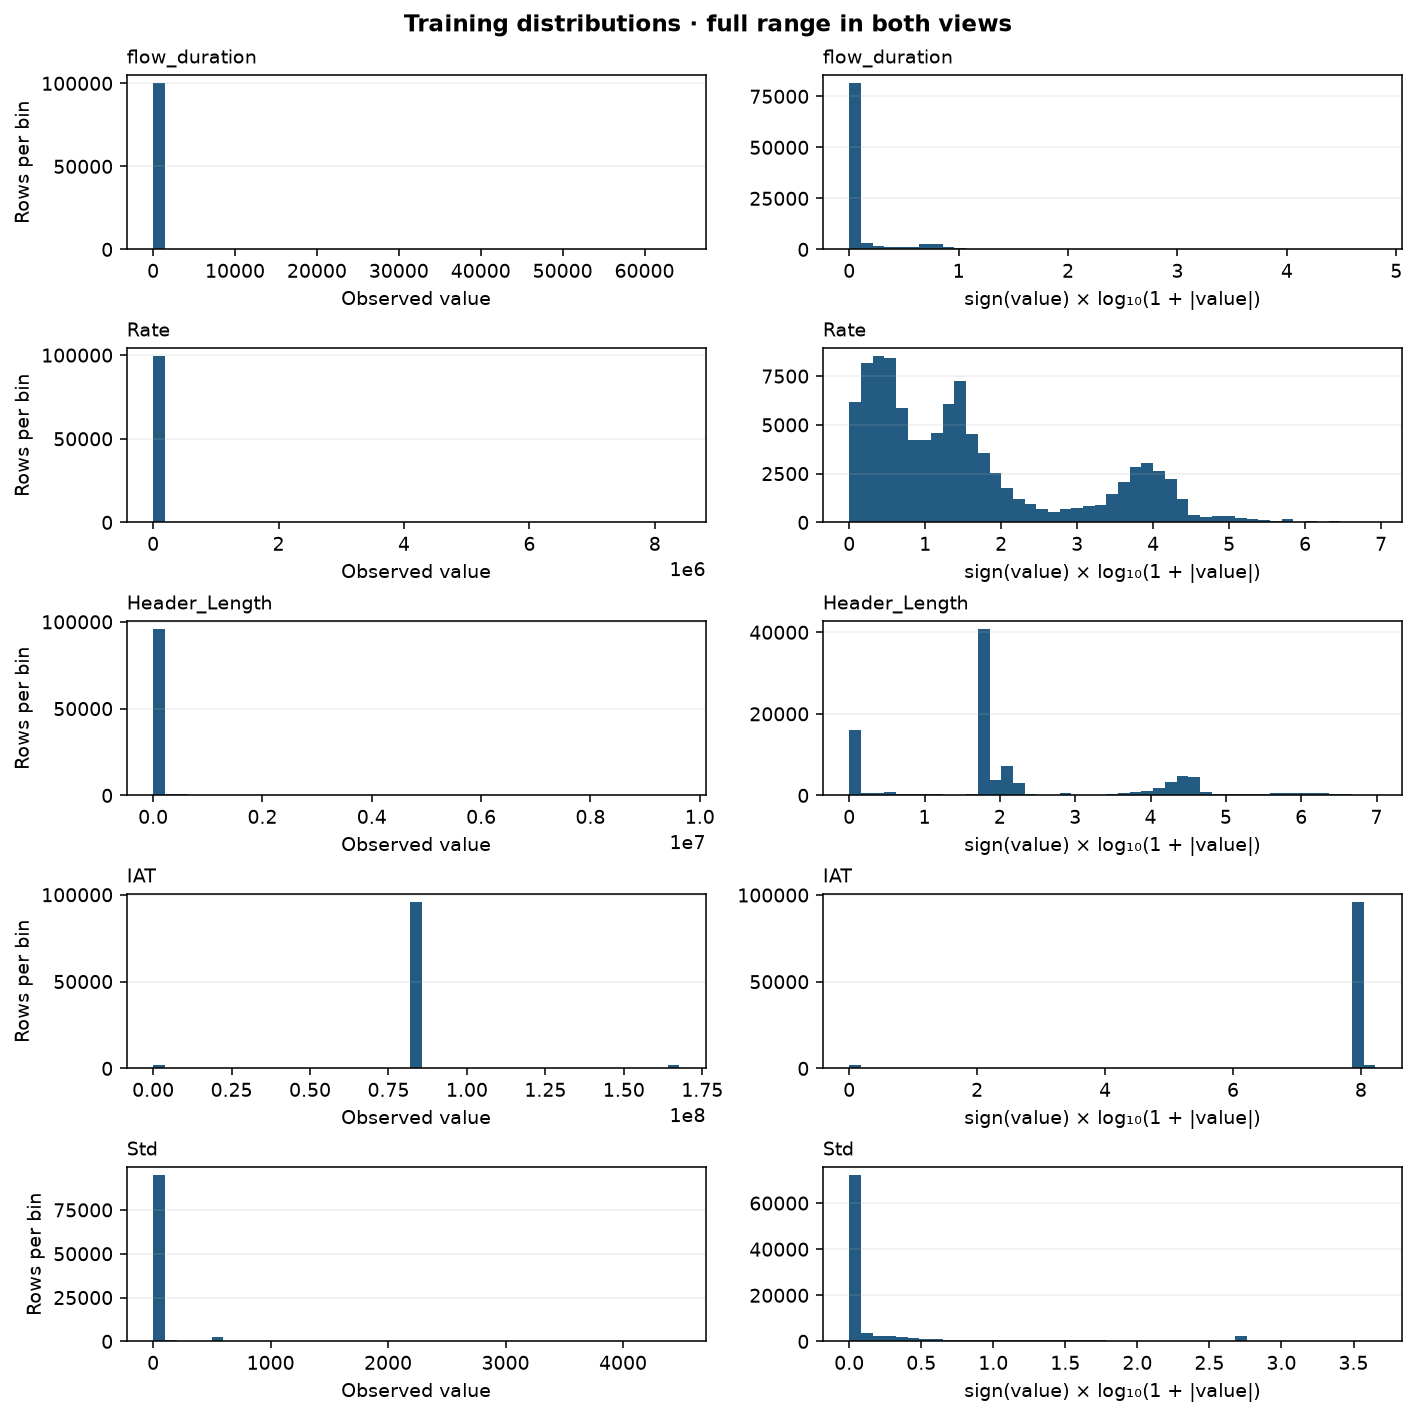

In [9]:
from io import BytesIO

import matplotlib.pyplot as plt
from IPython.display import Image

def show_eda_figure(figure):
    with BytesIO() as buffer:
        figure.savefig(buffer, format="png", dpi=140, bbox_inches="tight", facecolor="white")
        display(Image(data=buffer.getvalue()))
    plt.close(figure)

varying_features = features_eda.loc[:, unique_counts.gt(1)]
skewness = varying_features.skew().rename("Skewness")
skew_table = pd.concat([unique_counts.rename("Unique values"), skewness], axis=1).dropna()
skew_groups = {
    "Many observed values": measurement_columns,
    "Binary or other low cardinality": binary_columns + other_low_columns,
}
top_skew = pd.concat({
    group: skew_table.loc[columns].sort_values("Skewness", key=lambda values: values.abs(), ascending=False).head(5)
    for group, columns in skew_groups.items()
}, names=["Observed feature group", "Feature"])
with pd.option_context("display.float_format", "{:.2f}".format):
    display(top_skew)

distribution_features = ["flow_duration", "Rate", "Header_Length", "IAT", "Std"]
figure, axes = plt.subplots(len(distribution_features), 2, figsize=(10, 10), layout="constrained")
figure.suptitle("Training distributions · full range in both views", fontweight="bold")
for feature, (linear_ax, log_ax) in zip(distribution_features, axes, strict=True):
    values = features_eda[feature].to_numpy()
    signed_log = np.sign(values) * np.log10(1 + np.abs(values))
    for ax, view in [(linear_ax, values), (log_ax, signed_log)]:
        ax.hist(view, bins=45, color="#245b82")
        ax.set_title(feature, loc="left", fontsize=10)
        ax.grid(axis="y", alpha=0.2)
    linear_ax.set_ylabel("Rows per bin")
    linear_ax.set_xlabel("Observed value")
    log_ax.set_xlabel("sign(value) × log₁₀(1 + |value|)")
show_eda_figure(figure)

**Finding.** `flow_duration` had the largest absolute skew among features with more than 10 values (128.3). The training median for `flow_duration` was 0, compared with a P99 of 65.7. For `Rate`, the median was 15.9 and P99 was 1.29e+05. Both views use every value (0 excluded). Rare indicator states can also produce large skew values. Extreme observations need extraction context, and skewness alone does not justify a transformation.

## Feature relationships

Use Spearman rank correlations to identify monotonic relationships among nonconstant training features. Inspect the strongest unique pairs and separately check exact equality for `Rate` and `Srate`.

,Feature 1,Feature 2,Spearman ρ
0,Rate,Srate,1.0000
1,IPv,LLC,1.0000
2,Radius,Covariance,0.9996
3,Number,Weight,0.9976
4,AVG,Magnitue,0.9974
5,AVG,Tot size,0.9926
6,Tot size,Magnitue,0.9910
7,Std,Radius,0.9905


,Check,Result
0,Rate equals Srate in every training row,True


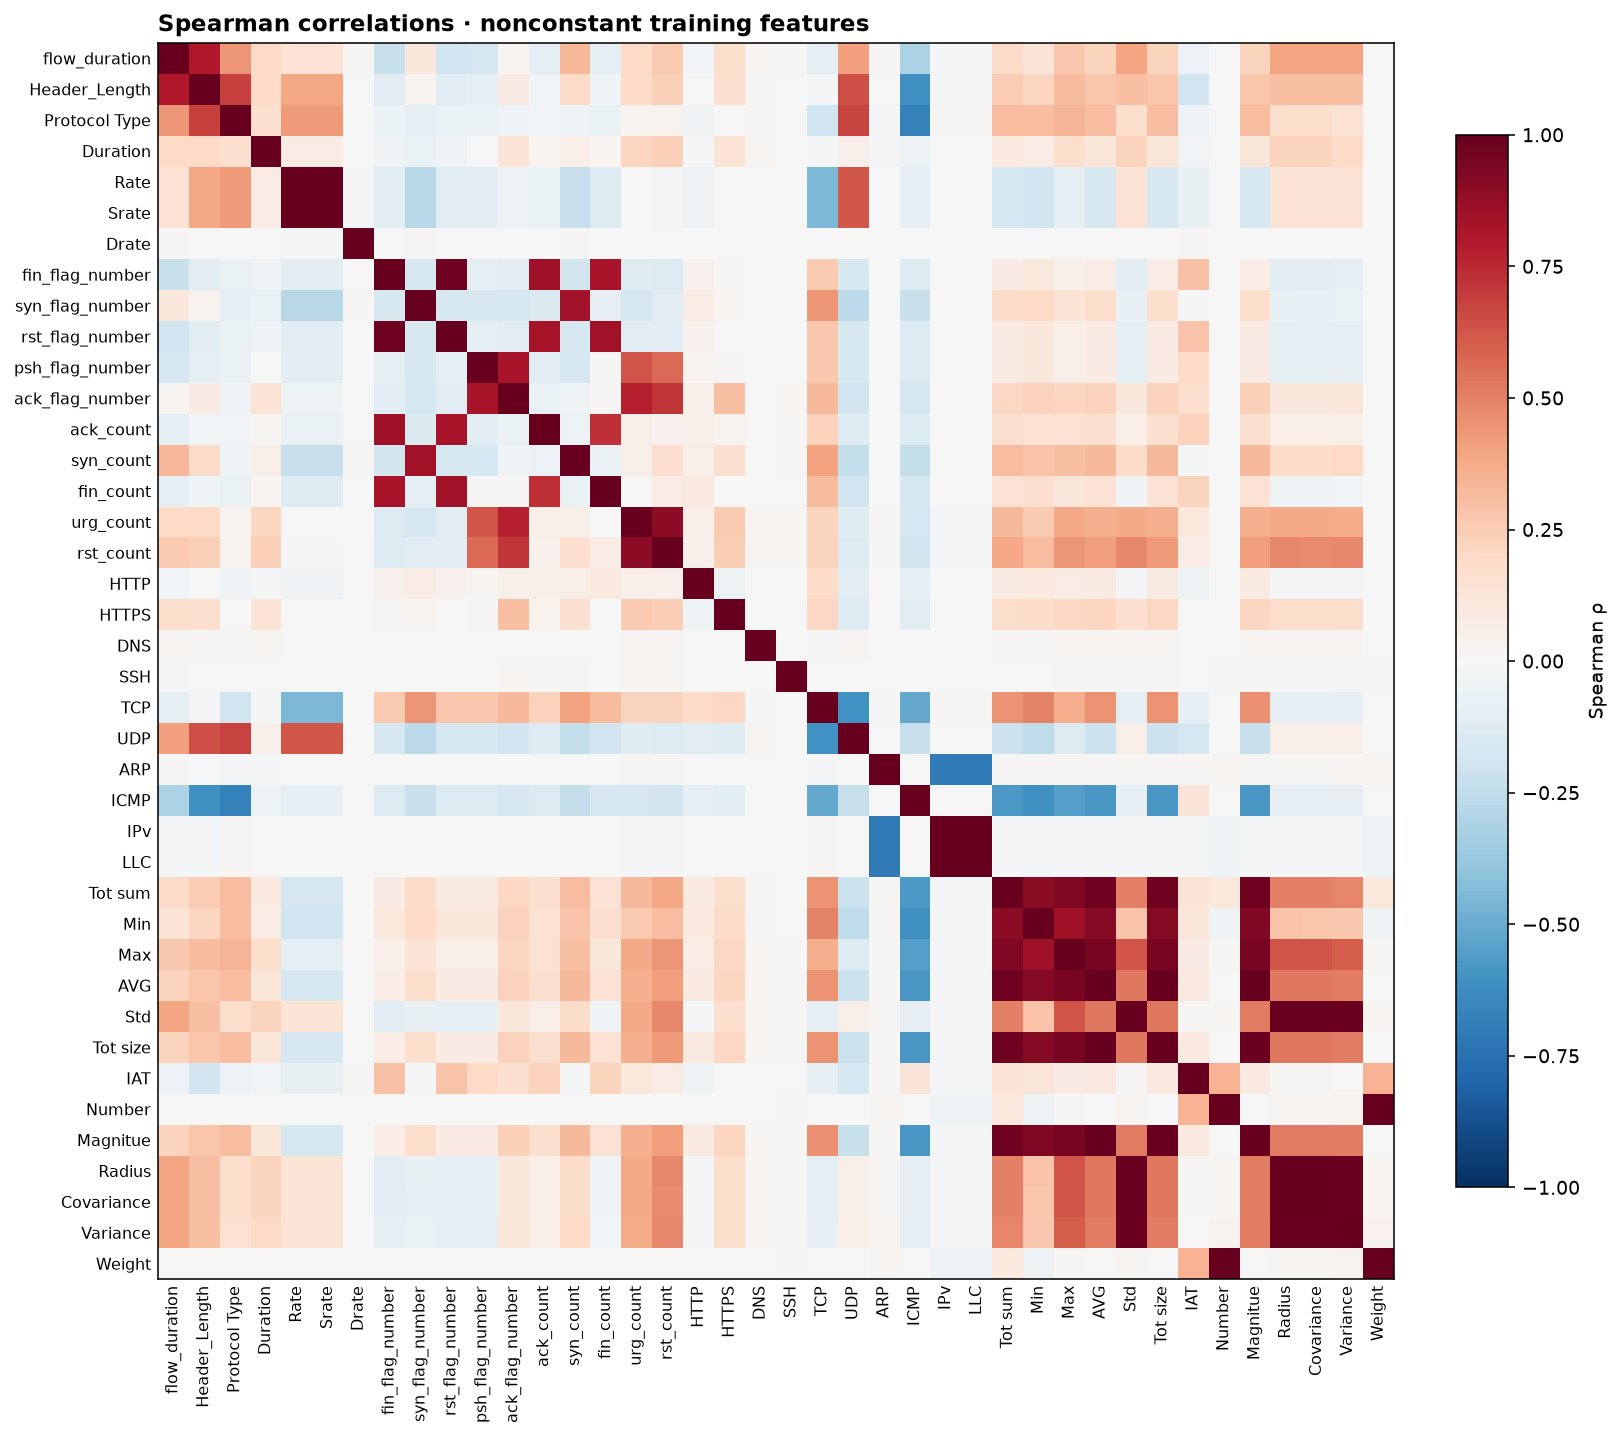

In [10]:
spearman_train = varying_features.corr(method="spearman")
row_idx, col_idx = np.triu_indices(len(spearman_train), k=1)
strongest_pairs = pd.DataFrame({
    "Feature 1": spearman_train.index[row_idx],
    "Feature 2": spearman_train.columns[col_idx],
    "Spearman ρ": spearman_train.to_numpy()[row_idx, col_idx],
}).sort_values("Spearman ρ", key=lambda values: values.abs(), ascending=False).head(8)
with pd.option_context("display.float_format", "{:.4f}".format):
    display(strongest_pairs.reset_index(drop=True))

rate_equal = None
if {"Rate", "Srate"}.issubset(features_eda.columns):
    rate_equal = bool(features_eda["Rate"].eq(features_eda["Srate"]).all())
    display(pd.DataFrame({"Check": ["Rate equals Srate in every training row"], "Result": [rate_equal]}))

figure, ax = plt.subplots(figsize=(11.5, 10.5), layout="constrained")
heatmap = ax.imshow(spearman_train, cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest")
positions = np.arange(len(spearman_train))
ax.set_xticks(positions, labels=spearman_train.columns, rotation=90, fontsize=8)
ax.set_yticks(positions, labels=spearman_train.index, fontsize=8)
ax.tick_params(length=0)
ax.set_title("Spearman correlations · nonconstant training features", loc="left", fontweight="bold")
figure.colorbar(heatmap, ax=ax, shrink=0.78, label="Spearman ρ")
show_eda_figure(figure)

**Finding.** `Rate` and `Srate` were exactly equal in every training row. `IPv` and `LLC` also had a strong rank association (ρ = 1.0000). These results flag possible redundancy. Correlation does not establish causation or justify removing a feature by itself.

## Benign-versus-attack comparisons

Match the CSV label spellings to the documented attack types before forming a plot-only group. Compare `flow_duration`, `Rate`, `Header_Length`, and `IAT` for their different measurement roles. Each curve shows the share of its own group at or below a value, so the larger group does not dominate.

[CIC dataset documentation](https://www.unb.ca/cic/datasets/iotdataset-2023.html) · [Dataset paper, packet-window aggregation](https://doi.org/10.3390/s23135941)

,Observed labels,Matched attack labels,Unverified labels
0,34,33,None


,Training rows
Plot group,
Documented attack labels,97641
Benign,2359


,flow_duration,Rate,Header_Length,IAT
Plot group,,,,
Benign,26.973,52.943,5.0462e+05,0.052018
Documented attack labels,0,15.033,54,8.3125e+07


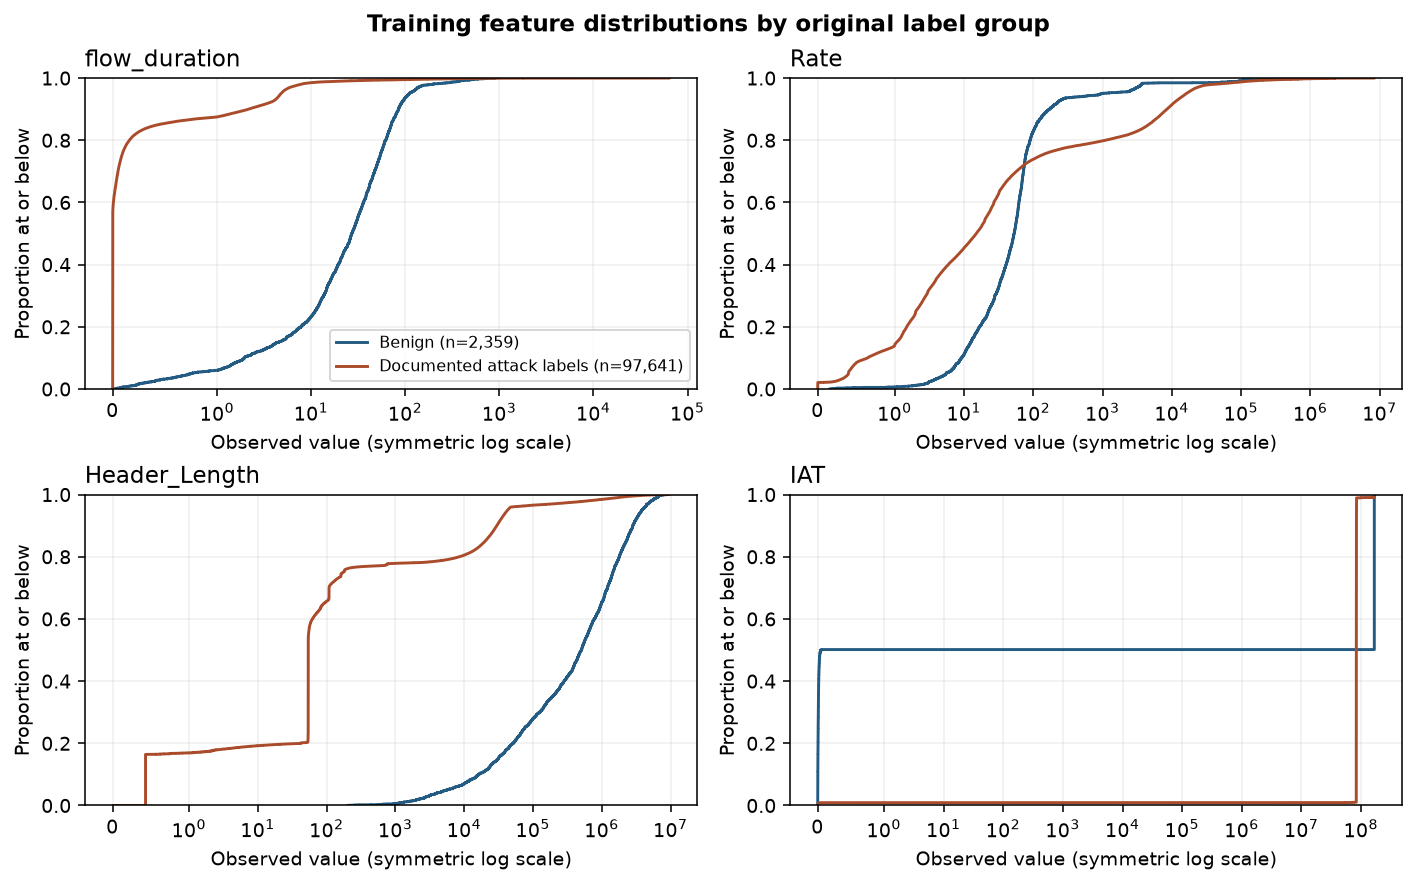

In [11]:
# CSV spellings of the 33 attack types listed by CIC and the dataset paper.
documented_attack_labels = {
    "DDoS-ACK_Fragmentation", "DDoS-HTTP_Flood", "DDoS-ICMP_Flood",
    "DDoS-ICMP_Fragmentation", "DDoS-PSHACK_Flood", "DDoS-RSTFINFlood",
    "DDoS-SYN_Flood", "DDoS-SlowLoris", "DDoS-SynonymousIP_Flood",
    "DDoS-TCP_Flood", "DDoS-UDP_Flood", "DDoS-UDP_Fragmentation",
    "DoS-HTTP_Flood", "DoS-SYN_Flood", "DoS-TCP_Flood", "DoS-UDP_Flood",
    "Recon-HostDiscovery", "Recon-OSScan", "Recon-PingSweep",
    "Recon-PortScan", "VulnerabilityScan",
    "Backdoor_Malware", "BrowserHijacking", "CommandInjection",
    "SqlInjection", "Uploading_Attack", "XSS", "DictionaryBruteForce",
    "DNS_Spoofing", "MITM-ArpSpoofing",
    "Mirai-greeth_flood", "Mirai-greip_flood", "Mirai-udpplain",
}
original_labels = training_eda["label"]
benign_label = "BenignTraffic"
observed_labels = set(original_labels.unique())
unverified_labels = observed_labels - documented_attack_labels - {benign_label}
other_group = "Other labelled traffic" if unverified_labels else "Documented attack labels"
plot_groups = pd.Series(
    np.where(original_labels.eq(benign_label), "Benign", other_group),
    index=original_labels.index,
    name="Plot group",
)
group_sizes = plot_groups.value_counts()
display(pd.DataFrame({
    "Observed labels": [len(observed_labels)],
    "Matched attack labels": [len(observed_labels & documented_attack_labels)],
    "Unverified labels": [", ".join(sorted(map(str, unverified_labels))) or "None"],
}))
display(group_sizes.rename("Training rows").to_frame())

comparison_features = ["flow_duration", "Rate", "Header_Length", "IAT"]
group_medians = features_eda[comparison_features].groupby(plot_groups).median()
with pd.option_context("display.float_format", "{:.5g}".format):
    display(group_medians)

figure, axes = plt.subplots(2, 2, figsize=(10, 6.2), layout="constrained")
figure.suptitle("Training feature distributions by original label group", fontweight="bold")
for feature, ax in zip(comparison_features, axes.flat, strict=True):
    for group, color in [("Benign", "#245b82"), (other_group, "#aa4c2b")]:
        values = features_eda.loc[plot_groups.eq(group), feature]
        ax.ecdf(values, compress=True, color=color, label=f"{group} (n={len(values):,})")
    ax.set_xscale("symlog", linthresh=1)
    ax.set_xlabel("Observed value (symmetric log scale)")
    ax.set_ylabel("Proportion at or below")
    ax.set_title(feature, loc="left")
    ax.grid(alpha=0.2)
axes[0, 0].legend(loc="lower right", fontsize=8)
show_eda_figure(figure)

**Finding.** All 33 non-benign labels matched documented attack types. The groups contained 2,359 benign and 97,641 attack-labelled rows. The benign median `Rate` was 52.9, compared with 15 for the attack-labelled group. The curves include all training rows (0 excluded). Differences may reflect the mix of attack types and do not establish predictive performance.

## EDA findings and decisions before modelling

- The three original files in this project contain **7,845,673 rows** and 47 columns. The saved train, validation, and test subsets contain **100,000 / 25,000 / 25,000 rows**. Proportional stratification retained all 34 labels and kept the largest per-label share change below 0.003 percentage points in each split. It preserved the imbalance. Training has 2.36% benign rows, and `Uploading_Attack` has only three training examples.
- The subsets contain zero missing or infinite cells. They contain **43 / 4 / 6** extra exact full-row copies in train, validation, and test. The split pairs share **25 / 19 / 5** exact feature patterns in train–validation, train–test, and validation–test order. The earlier exact-string audit in [01_dataset_inspection.ipynb](01_dataset_inspection.ipynb) reported 57,847 distinct full rows shared by train and test. Verification under parsed numeric equality and decisions about overlap handling remain unresolved. Subset matches do not establish independence of the full splits.
- Training has 6 constant features. Several measurements have long right tails, and `Rate` equals `Srate` throughout the sample. Verify units, extraction windows, and the meanings of rate, flag, and timing fields against the extraction implementation for these CSVs. Record-level replay without verified chronology or capture provenance cannot validate temporal behaviour or real alert timing.
- Before modelling, agree on how to handle exact overlap and duplicates, what preprocessing is justified, and what grouping or chronology the evaluation can support. Keep the test set for final evaluation and fit any preprocessing on training data only.
- For a future binary evaluation, report the confusion matrix, precision, recall, and F1 for each class (treat each class as positive when computing its own metrics), and balanced accuracy. With **attack as the positive class** for the confusion matrix, the benign false-positive rate is the share of actual benign records flagged as attacks, FP / (FP + TN).